In [37]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import umap
from sklearn.cluster import KMeans
from solution_utils import build_tables, get_users_text, vectorize_topic_texts, SEED
from sklearn.metrics import homogeneity_score, completeness_score, silhouette_score, adjusted_rand_score

In [23]:
data = pd.read_json('hw1_train.jsonl', lines=True)

data

,dialog_id,language,n_user_turns,turns,labels
0,d094012177e,en,7,"[{'role': 'user', 'text': 'it’s like: 1+1=2, b...","{'task_type': 'analysis', 'reaction': 'positiv..."
1,d306fbe61fe,en,8,"[{'role': 'user', 'text': 'Can you help me tra...","{'task_type': 'information_seeking', 'reaction..."
2,dd6905952c7,en,5,"[{'role': 'user', 'text': 'ask questions about...","{'task_type': 'creation', 'reaction': 'neutral..."
3,d767a675896,en,6,"[{'role': 'user', 'text': 'Calculate each prom...","{'task_type': 'information_seeking', 'reaction..."
4,d7a6280ce8e,en,8,"[{'role': 'user', 'text': 'mass spectrometer, ...","{'task_type': 'information_seeking', 'reaction..."
...,...,...,...,...,...
9995,d745e2d0b74,en,8,"[{'role': 'user', 'text': 'which countries off...",None
9996,d2248b50e1e,en,6,"[{'role': 'user', 'text': 'Medication safety, ...",None
9997,dba01d56b0d,en,10,"[{'role': 'user', 'text': 'Your instructions a...",None
9998,d07a2ffacb8,en,5,"[{'role': 'user', 'text': 'write a story for p...",None


In [24]:
print(f'доля записей с labels {data['labels'].notna().mean()}')
data = data.drop(columns='labels')

доля записей с labels 0.3


ответы нейронки смотреть смысла нет, так как пользователь задаёт тему и ведет её, нейронка только поддакивает

In [25]:
dialogs, turn = build_tables(data.to_dict('records'))

user = dialogs.iloc[0, 2]

# for replica in user:
#     print(replica)

print (user[0])

dialogs

i


,language,n_user_turns,user_text,assistant_text,user_len,assistant_len,reaction,task_type
dialog_id,,,,,,,,
d094012177e,en,7,"it’s like: 1+1=2, but 1+1=2+1+1=? is undefined...",Introducing scientific terms from astrophysics...,8453,10492,None,None
d306fbe61fe,en,8,Can you help me train a small language model t...,Creating a small language model from scratch i...,1278,32255,None,None
dd6905952c7,en,5,ask questions about a fictional voice actor i ...,1. How did this fictional voice actor get into...,3326,11938,None,None
d767a675896,en,6,Calculate each prompt based off of data and sh...,"To calculate Species Richness, simply count th...",1115,9253,None,None
d7a6280ce8e,en,8,"mass spectrometer, the length of AC rod will i...",As an AI language model I don't have enough in...,374,7528,None,None
...,...,...,...,...,...,...,...,...
d745e2d0b74,en,8,which countries offer special programs to enco...,There are several countries that offer special...,433,11913,None,None
d2248b50e1e,en,6,"Medication safety, \n\nMedication administrati...",This documentation is important in ensuring co...,2776,5259,None,None
dba01d56b0d,en,10,Your instructions are: For the following quest...,"As an AI language model, I do not possess the ...",995,8526,None,None


In [50]:
user_text = get_users_text(data.to_dict('records'), text_type='user')

key_words_classterize = [] # будет хранить диалоги по которым будем кластеризовать
for payload in user_text['text']:
    key_words_classterize.append(payload[:2])

key_words_classterize

[['it’s like: 1+1=2, but 1+1=2+1+1=? is undefined. <–can you tell which modulus we can possibly use in this concept and into which it may result?\nIn the context of the equation “1+1=2+1+1=?,” if we want to explore the possibility of using a modulus to determine the result, we can consider different modulus values and see how they affect the equation.\n\nModulus, also known as the remainder when dividing a number by another, is often denoted by the symbol “%”. It can be used to find the remainder of a division operation.\n\nLet’s consider a few examples:\n\n1. Modulus 3:\nUsing modulus 3, we would evaluate remainders when dividing numbers by 3. Therefore:\n1 + 1 = 2 % 3 + 1 % 3 + 1 % 3\n= 2 + 1 + 1\n= 4\n\n2. Modulus 4:\nUsing modulus 4, we would evaluate remainders when dividing numbers by 4. Therefore:\n1 + 1 = 2 % 4 + 1 % 4 + 1 % 4\n= 2 + 1 + 1\n= 4\n\n3. Modulus 5:\nUsing modulus 5, we would evaluate remainders when dividing numbers by 5. Therefore:\n1 + 1 = 2 % 5 + 1 % 5 + 1 % 5\n

# мой план:
1) сделать векторизацию tf-idf 
2) подбирать кластеры kmeans++
3)  сравнивать метрики (силуэт и тд)
4) назвать темы 
5) проверть при более полном наборе диалогов
6) утвердить окончательно
7) сделать тествоую выборку (разметить темы самому)
8) обучать, сравнивать, деплоить

In [51]:
X,  tf_idfer = vectorize_topic_texts(key_words_classterize) # наши диалоги в циферках


In [52]:
reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, metric='cosine', random_state=SEED)

X_umap = reducer.fit_transform(X)

plt.figure(figsize=(10, 7))
plt.scatter(X_umap[:, 0], X_umap[:, 1], s=10, alpha=0.7)

plt.title('UMAP visualization raw data')
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2')
plt.show()

/Users/var/Documents/projects/meow/HW/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


SystemError: CPUDispatcher(<function nn_descent at 0x161e561f0>) returned a result with an exception set

In [53]:
empty_mask = np.asarray(X.getnnz(axis=1) == 0).ravel()
print("Диалогов без TF-IDF-признаков:", empty_mask.sum())

Диалогов без TF-IDF-признаков: 49


а что это за диалоги?

In [54]:
empty_indices = np.where(empty_mask)[0]

for i in empty_indices[:20]:
    print(f"Индекс: {i}")
    print(repr(key_words_classterize[i]))
    print("---")

Индекс: 353
['chào cậu', 'có']
---
Индекс: 425
['Bello', 'S']
---
Индекс: 551
['食べましたが', 'にほんご\u3000できる？']
---
Индекс: 685
['hehehehhee', 'Muwahahahahaha']
---
Индекс: 766
['你是英语翻译方面的专家。请将下面的句子翻译为英语：\n在访学期间，我经常去杨老师的实验室，与杨老师和他的学生讨论一些研究。我发现这个对我的帮助很大，访学期间我和杨老师在TSE上合作发表了一篇论文。开展了充分的合作。我回国后，依然与他着合作关系。到目前位置，我们一起合作了4-5篇期刊论文。我特别喜欢密西根州，那边环境优美、比较宁静，人们也比较友好、夏天不热、冬天也不太冷。我在那边认识了几个朋友，现在还保持着联系。', '你是英语翻译方面的专家。请将下面的句子翻译为英语：\n我曾经访问过西密歇根大学。访学开始于2018年9月，结束语2019年1月。在访学期间，我经常去杨老师的实验室，与杨老师和他的学生讨论一些研究。我发现这个对我的帮助很大，访学期间我和杨老师在TSE上合作发表了一篇论文。开展了充分的合作。我回国后，依然与他着合作关系。到目前位置，我们一起合作了4-5篇期刊论文。我特别喜欢密西根州，那边环境优美、比较宁静，人们也比较友好、夏天不热、冬天也不太冷。我在那边认识了几个朋友，现在还保持着联系。']
---
Индекс: 1199
['ขอรายชื่ออาหารที่ช่วยบรรเทาอาการซึมเศร้า', "What's แฮปปี้โฟล์ก, แอสไพริน, โนซัลตริปไทฟานีน, เบรนท์เจอร์ลี่ and วอโลเนีย"]
---
Индекс: 1674
['窦性心动过缓英文', 'What is sinus bradycardia']
---
Индекс: 1752
['变形金刚5：最后的骑士 主要内容', '名侦探柯南：业火的向日葵 主要内容']
---
Индекс: 1760
['我昨天通过FAR DAR给fr寄了测量工具，现在想发英语邮件告诉他们，要怎么说。', '是要告诉fr']
---
Индекс: 1771
['这个实验室从一种名为蒙特卡罗采样的技

In [66]:
scores_silhuet = []
for k in range (3, 15):
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, max_iter=300, random_state=SEED)
    cluster_labels = kmeans.fit_predict(X)

    scores_silhuet.append((k, silhouette_score(X, cluster_labels, random_state=SEED, sample_size=None, metric='euclidean')))

score_table = pd.DataFrame(scores_silhuet, columns=["k", "silhouette_score"])
print(score_table)

     k  silhouette_score
0    3          0.001648
1    4          0.002247
2    5          0.002576
3    6          0.003163
4    7          0.003202
5    8          0.003855
6    9          0.003670
7   10          0.004217
8   11          0.004380
9   12          0.004313
10  13          0.004490
11  14          0.004928


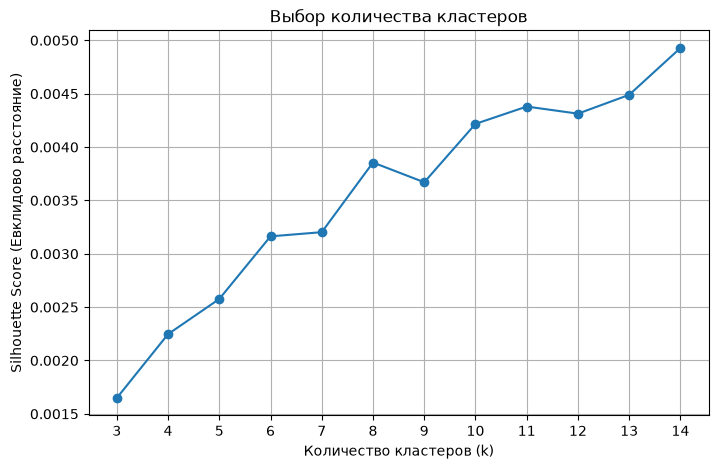

In [58]:
plt.figure(figsize=(8, 5))
plt.plot(score_table["k"], score_table["silhouette_score"], marker="o")

plt.xlabel("Количество кластеров (k)")
plt.ylabel("Silhouette Score (Евклидово расстояние)")
plt.title("Выбор количества кластеров")
plt.xticks(score_table["k"])
plt.grid(True)
plt.show()

мда, силуэт порядка 0,001 это конечно сильно. можно попробовать глянуть косинусное расстояние для сравнения, а потом переходить к рассмотрению полных диалогов user и может быть даже к user+assistant

In [ ]:
scores_silhuet_cos = []
for k in range (3, 15):
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, max_iter=300, random_state=SEED)
    cluster_labels_cos = kmeans.fit_predict(X)

    scores_silhuet_cos.append((k, silhouette_score(X, cluster_labels_cos, random_state=SEED, sample_size=None, metric='cosine')))

score_table_cos = pd.DataFrame(scores_silhuet_cos, columns=["k", "silhouette_score"])

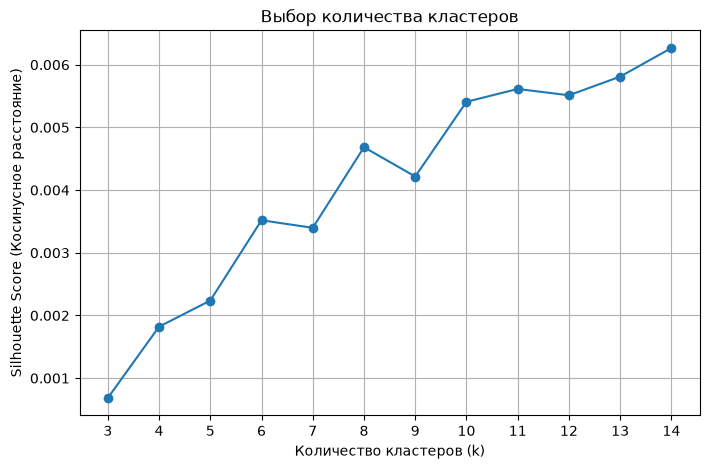

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(score_table_cos["k"], score_table_cos["silhouette_score"], marker="o")

plt.xlabel("Количество кластеров (k)")
plt.ylabel("Silhouette Score (Косинусное расстояние)")
plt.title("Выбор количества кластеров")
plt.xticks(score_table_cos["k"])
plt.grid(True)
plt.show()

в целом этого следовало ожидать, не, ну а вдруг) 
переходим к обучению на всех текстах user'a

In [ ]:
key_words_classterize_all_user = [] # будет хранить диалоги по которым будем кластеризовать
for payload in user_text['text']:
    key_words_classterize_all_user.append(payload)

X_all_user,  tf_idfer_all_user = vectorize_topic_texts(key_words_classterize_all_user) # наши диалоги в циферках

empty_mask = np.asarray(X_all_user.getnnz(axis=1) == 0).ravel()
print("Диалогов без TF-IDF-признаков:", empty_mask.sum())

scores_silhuet_all_user = []
for k in range (3, 15):
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, max_iter=300, random_state=SEED)
    cluster_labels_all_user = kmeans.fit_predict(X)

    scores_silhuet_all_user.append((k, silhouette_score(X, cluster_labels_all_user, random_state=SEED, sample_size=None, metric='euclidean')))

score_table_all_user = pd.DataFrame(scores_silhuet_all_user, columns=["k", "silhouette_score"])
print(score_table_all_user)

Диалогов без TF-IDF-признаков: 0
     k  silhouette_score
0    3          0.001313
1    4          0.001192
2    5          0.001165
3    6          0.001814
4    7          0.001037
5    8          0.001998
6    9          0.001493
7   10          0.001581
8   11          0.002329
9   12          0.002502
10  13          0.002950
11  14          0.002951


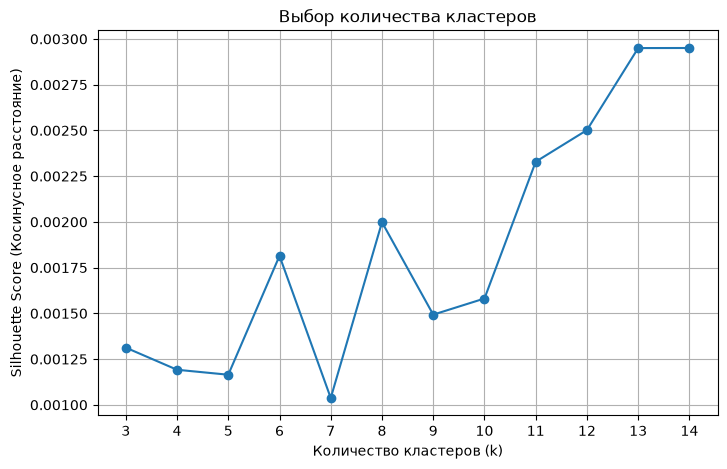

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(score_table_all_user["k"], score_table_all_user["silhouette_score"], marker="o")

plt.xlabel("Количество кластеров (k)")
plt.ylabel("Silhouette Score (Косинусное расстояние)")
plt.title("Выбор количества кластеров")
plt.xticks(score_table_all_user["k"])
plt.grid(True)
plt.show()

вернемся к пользователям с обрезанными диалогами и будем пытаться что-то с этим сделать

In [63]:
kmeans = KMeans(n_clusters=8, init='k-means++', n_init=10, max_iter=300, random_state=SEED)
cluster_labels = kmeans.fit_predict(X)

In [71]:
data

,dialog_id,language,n_user_turns,turns
0,d094012177e,en,7,"[{'role': 'user', 'text': 'it’s like: 1+1=2, b..."
1,d306fbe61fe,en,8,"[{'role': 'user', 'text': 'Can you help me tra..."
2,dd6905952c7,en,5,"[{'role': 'user', 'text': 'ask questions about..."
3,d767a675896,en,6,"[{'role': 'user', 'text': 'Calculate each prom..."
4,d7a6280ce8e,en,8,"[{'role': 'user', 'text': 'mass spectrometer, ..."
...,...,...,...,...
9995,d745e2d0b74,en,8,"[{'role': 'user', 'text': 'which countries off..."
9996,d2248b50e1e,en,6,"[{'role': 'user', 'text': 'Medication safety, ..."
9997,dba01d56b0d,en,10,"[{'role': 'user', 'text': 'Your instructions a..."
9998,d07a2ffacb8,en,5,"[{'role': 'user', 'text': 'write a story for p..."


In [88]:
dialog_table_to_analyze = []
for theme_idx in range(8):
    indexes = cluster_labels == theme_idx
    themed_dialog = data[indexes]

    print(f"Кластер {theme_idx}, количество диалогов: {len(themed_dialog)}")

    n_samples = min(5, len(themed_dialog))

    if n_samples > 0:
        selected_indices = np.random.choice(
            len(themed_dialog),
            size=n_samples,
            replace=False
        )
        get_dialog = themed_dialog.iloc[selected_indices].values.tolist()
    else:
        get_dialog = []

    dialog_table_to_analyze.append((theme_idx, get_dialog))

dialog_table_to_analyze = pd.DataFrame(dialog_table_to_analyze, columns=["theme", "dialog"])

Кластер 0, количество диалогов: 82
Кластер 1, количество диалогов: 723
Кластер 2, количество диалогов: 794
Кластер 3, количество диалогов: 457
Кластер 4, количество диалогов: 837
Кластер 5, количество диалогов: 540
Кластер 6, количество диалогов: 3660
Кластер 7, количество диалогов: 138


In [ ]:
# 0 - chat gpt (есть в мире дураки (выбросы))
# 1 - games (иногда заигрывания 😏)
# 2 - программирование (очень хорошо распределил)
# 3 - просьбы что-то сделать? (упомянается конкретное действие)
# 4 - просьба что-то расчитать, прикинуть (что-то люто непонятное)
# 5 - что-то для школьников/простое (возможно выбросы)
# 6 - Упомянаются какие-то люди
# 7 - хрень не на русском (обычно что-то перевести или реально запросы)
dialog_table_to_analyze['dialog'][7]

[['d1c3cc92313',
  'en',
  9,
  [{'role': 'user',
    'text': 'Translate to Japanese\n\n"Sea of The Last Son"\n\n"Last Son" is a name.'},
   {'role': 'assistant', 'text': '"ラスト・サンの海" (Rasuto San no Umi)'},
   {'role': 'user', 'text': '"Son" as in a male child, not "Sun.'},
   {'role': 'assistant',
    'text': 'My apologies for the oversight. If "Last Son" is treated as a name and you want to maintain that name in the original English within a Japanese context, you would translate "Sea of The Last Son" to Japanese as:\n\nラスト・サンの海\n\nIf you want to translate "Son" to make it clear that it refers to a male child, you could potentially use "息子" (musuko), which means son. However, it is not common to translate proper names that way. If "Last Son" is strictly a name, it\'s usually kept in the original form even when the surrounding context is translated.'},
   {'role': 'user',
    'text': 'You did it again. What is the Japanese word for "Son"?'},
   {'role': 'assistant',
    'text': 'Apologi